<a href="https://colab.research.google.com/github/nandasutaj/siemen_energy/blob/main/siemen_energy_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Energy Clustering

UCS321 | Project 10 | Siemens Energy case study

The aim is to group electricity profiles with similar weekly patterns. The dataset is public and is not Siemens-owned data.

## Data

The CSV has 321 time series and 156 weekly readings per series. `series_id` is an identifier, not a model feature. Units for the aggregated weekly values are left as dataset units.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

file_path = Path("electricity_weekly_wide.csv")
if not file_path.exists():
    from google.colab import files
    uploaded = files.upload()
    file_path = Path(next(name for name in uploaded if name.endswith(".csv")))

df = pd.read_csv(file_path)
week_columns = [c for c in df.columns if c.startswith("Week_")]
X_raw = df[week_columns].astype(float)

print("Shape:", df.shape)
print("Series:", df["series_id"].nunique())
print("Weekly columns:", len(week_columns))

Saving Siemens_Energy_Clustering Dataset.csv to Siemens_Energy_Clustering Dataset (1).csv
Shape: (321, 158)
Series: 321
Weekly columns: 156


## Checks

The data has no missing or negative measurements. Three profiles contain zeros; the next cells look at them before modelling.

In [ ]:
checks = pd.Series({
    "Missing values": int(X_raw.isna().sum().sum()),
    "Negative values": int((X_raw < 0).sum().sum()),
    "Zero values": int((X_raw == 0).sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Unique IDs": int(df["series_id"].nunique())
})
display(checks.to_frame("Count"))

profile_stats = pd.DataFrame({
    "series_id": df["series_id"],
    "mean": X_raw.mean(axis=1),
    "median": X_raw.median(axis=1),
    "std": X_raw.std(axis=1),
    "max": X_raw.max(axis=1),
    "zero_weeks": (X_raw == 0).sum(axis=1)
})
profile_stats["cv"] = profile_stats["std"] / profile_stats["mean"].replace(0, np.nan)
display(profile_stats[profile_stats["zero_weeks"] > 0].round(3))

,Count
Missing values,0
Negative values,0
Zero values,206
Duplicate rows,0
Unique IDs,321


,series_id,mean,median,std,max,zero_weeks,cv
106,T107,35395.622,33157.0,18435.547,121639.0,6,0.521
182,T183,121731.404,0.0,216122.350,583203.0,117,1.775
298,T299,1791.942,0.0,2061.774,6284.0,83,1.151


## EDA

Average values are right-skewed. The profiles also differ in both level and variability.

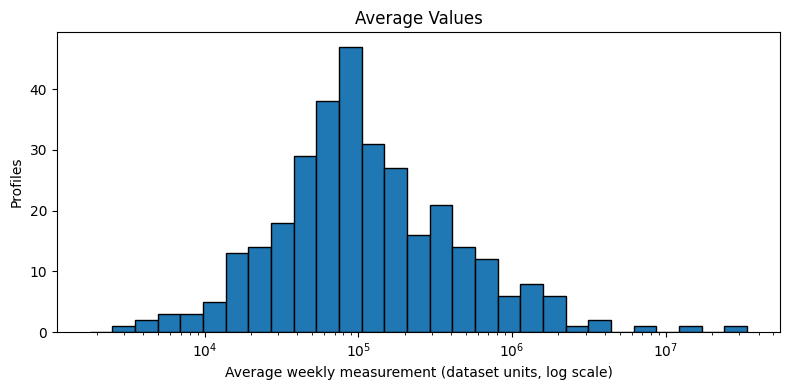

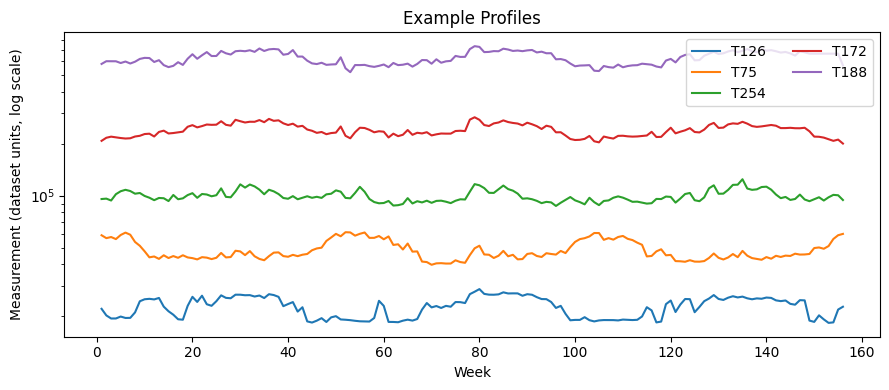

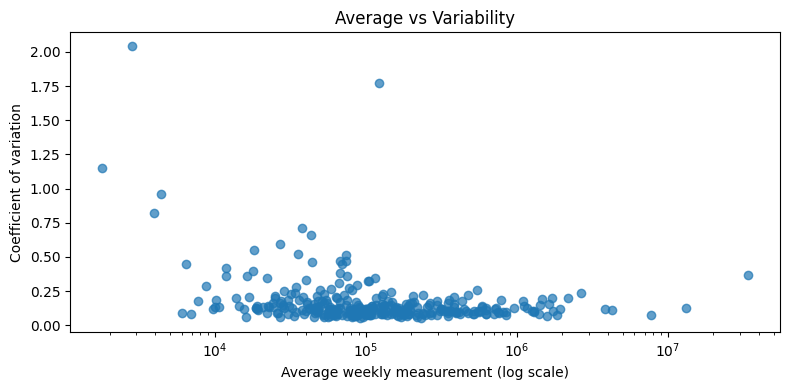

In [ ]:
positive_means = profile_stats.loc[profile_stats["mean"] > 0, "mean"]
bins = np.logspace(np.log10(positive_means.min()), np.log10(positive_means.max()), 30)
plt.figure(figsize=(8, 4))
plt.hist(positive_means, bins=bins, edgecolor="black")
plt.xscale("log")
plt.xlabel("Average weekly measurement (dataset units, log scale)")
plt.ylabel("Profiles")
plt.title("Average Values")
plt.tight_layout()
plt.show()


selected = []
for q in [0.1, 0.25, 0.5, 0.75, 0.9]:
    target = profile_stats["mean"].quantile(q)
    idx = (profile_stats["mean"] - target).abs().idxmin()
    if idx not in selected:
        selected.append(idx)

plt.figure(figsize=(9, 4))
for idx in selected:
    plt.plot(range(1, len(week_columns) + 1), X_raw.loc[idx].replace(0, np.nan), label=df.loc[idx, "series_id"])
plt.yscale("log")
plt.xlabel("Week")
plt.ylabel("Measurement (dataset units, log scale)")
plt.title("Example Profiles")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(profile_stats["mean"], profile_stats["cv"], alpha=0.7)
plt.xscale("log")
plt.xlabel("Average weekly measurement (log scale)")
plt.ylabel("Coefficient of variation")
plt.title("Average vs Variability")
plt.tight_layout()
plt.show()

## Cleaning

T183 is zero for 117 weeks and T299 for 83 weeks. I exclude these two from the main run because those long zero blocks could dominate the pattern comparison. T107 has six zero weeks and is kept. This is a modelling choice, not proof that the readings are wrong.

In [ ]:
zero_report = profile_stats.loc[profile_stats["zero_weeks"] > 0, ["series_id", "zero_weeks"]].copy()
zero_report["zero_percent"] = zero_report["zero_weeks"] / len(week_columns) * 100
display(zero_report.round(2))

exclude_ids = ["T183", "T299"]
mask = ~df["series_id"].isin(exclude_ids)
X = X_raw.loc[mask].copy().reset_index(drop=True)
series_ids = df.loc[mask, "series_id"].reset_index(drop=True)

print("Before:", X_raw.shape)
print("Excluded:", exclude_ids)
print("After:", X.shape)

,series_id,zero_weeks,zero_percent
106,T107,6,3.85
182,T183,117,75.00
298,T299,83,53.21


Before: (321, 156)
Excluded: ['T183', 'T299']
After: (319, 156)


## Features

I compared the original consumption level with profiles normalised by their own mean. The second version puts more focus on the shape of the weekly pattern.

In [ ]:
X_log = np.log1p(X)
X_level_scaled = StandardScaler().fit_transform(X_log)
pca_level = PCA().fit(X_level_scaled)

row_means = X.mean(axis=1)
X_shape = X.div(row_means.replace(0, np.nan), axis=0)
if X_shape.isna().any().any():
    raise ValueError("A profile has a zero or invalid mean.")
X_shape_scaled = StandardScaler().fit_transform(X_shape)
pca_shape = PCA().fit(X_shape_scaled)

feature_comparison = pd.DataFrame({
    "Version": ["Level", "Shape"],
    "PC1 (%)": [pca_level.explained_variance_ratio_[0] * 100,
                pca_shape.explained_variance_ratio_[0] * 100],
    "PC1+PC2 (%)": [pca_level.explained_variance_ratio_[:2].sum() * 100,
                    pca_shape.explained_variance_ratio_[:2].sum() * 100],
    "Components for 95%": [np.argmax(np.cumsum(pca_level.explained_variance_ratio_) >= .95) + 1,
                            np.argmax(np.cumsum(pca_shape.explained_variance_ratio_) >= .95) + 1]
})
display(feature_comparison.round(3))

,Version,PC1 (%),PC1+PC2 (%),Components for 95%
0,Level,96.833,97.787,1
1,Shape,27.841,44.935,25


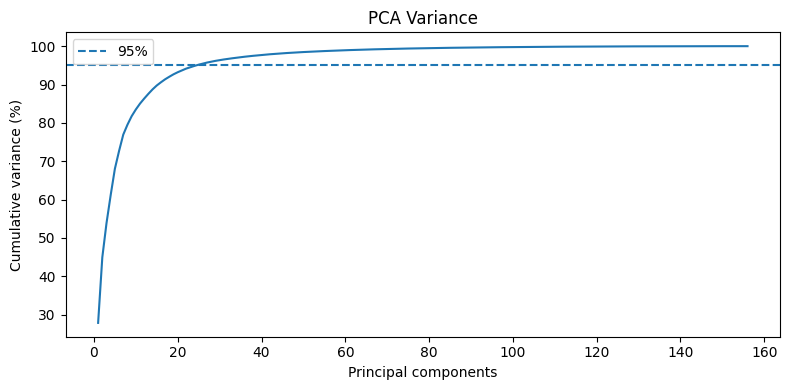

Components: 25
Variance kept: 95.173 %


In [ ]:
cum_shape = np.cumsum(pca_shape.explained_variance_ratio_)
n95 = int(np.argmax(cum_shape >= 0.95) + 1)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_shape) + 1), cum_shape * 100)
plt.axhline(95, linestyle="--", label="95%")
plt.xlabel("Principal components")
plt.ylabel("Cumulative variance (%)")
plt.title("PCA Variance")
plt.legend()
plt.tight_layout()
plt.show()

pca_95 = PCA(n_components=0.95, svd_solver="full")
X_pca_95 = pca_95.fit_transform(X_shape_scaled)
print("Components:", X_pca_95.shape[1])
print("Variance kept:", round(pca_95.explained_variance_ratio_.sum() * 100, 3), "%")

## K-Means

I tested K from 2 to 10. K=9 has the highest silhouette score, but creates several one-profile clusters. K=2 is used for the main result because its clusters are larger and easier to interpret; its separation is still only moderate.

,K,Inertia,Silhouette,Smallest cluster,Clusters below 5
0,2,38691.8963,0.3423,92,0
1,3,35320.6205,0.3490,13,0
2,4,32421.1927,0.3581,1,1
3,5,29682.8135,0.3578,1,2
4,6,26888.4353,0.3652,1,2
5,7,25516.0038,0.3308,1,3
6,8,22491.1461,0.3624,1,4
7,9,20974.3138,0.3677,1,5
8,10,20170.3382,0.3418,1,6


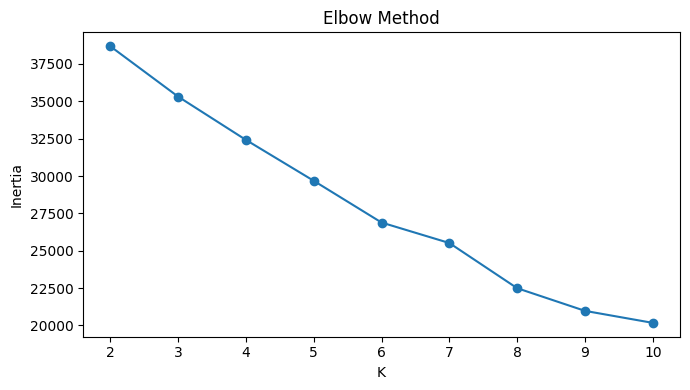

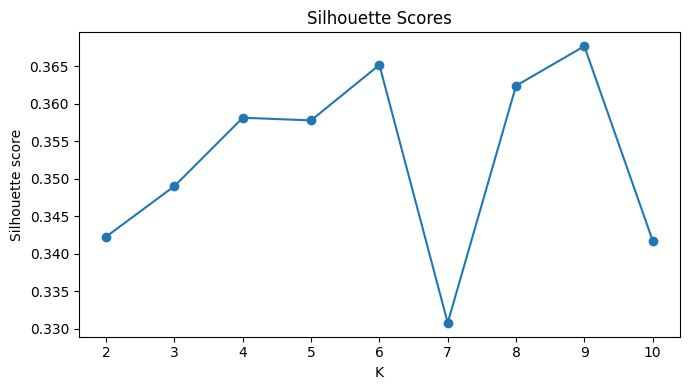

In [ ]:
k_values = range(2, 11)
rows = []
labels_by_k = {}

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca_95)
    sizes = pd.Series(labels).value_counts()
    rows.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_pca_95, labels),
        "Smallest cluster": int(sizes.min()),
        "Clusters below 5": int((sizes < 5).sum())
    })
    labels_by_k[k] = labels

model_results = pd.DataFrame(rows)
display(model_results.round(4))

plt.figure(figsize=(7, 4))
plt.plot(model_results["K"], model_results["Inertia"], marker="o")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(model_results["K"], model_results["Silhouette"], marker="o")
plt.xlabel("K")
plt.ylabel("Silhouette score")
plt.title("Silhouette Scores")
plt.tight_layout()
plt.show()

## Final Model

The main model uses two clusters and the 25 PCA components from the shape-based data.

In [ ]:
final_k = 2
kmeans_final = KMeans(n_clusters=final_k, random_state=42, n_init=10)
final_labels = kmeans_final.fit_predict(X_pca_95)
final_silhouette = silhouette_score(X_pca_95, final_labels)
sample_silhouette = silhouette_samples(X_pca_95, final_labels)

final_results = pd.DataFrame({
    "series_id": series_ids,
    "Cluster": final_labels,
    "Silhouette": sample_silhouette
})

print("Silhouette:", round(final_silhouette, 4))
display(final_results["Cluster"].value_counts().sort_index().rename("Profiles").to_frame())

display(final_results.groupby("Cluster").agg(
    Profiles=("series_id", "count"),
    Mean_silhouette=("Silhouette", "mean"),
    Negative_scores=("Silhouette", lambda s: int((s < 0).sum()))
).round(4))

Silhouette: 0.3423


,Profiles
Cluster,
0,227
1,92


,Profiles,Mean_silhouette,Negative_scores
Cluster,,,
0,227,0.3918,0
1,92,0.2202,11


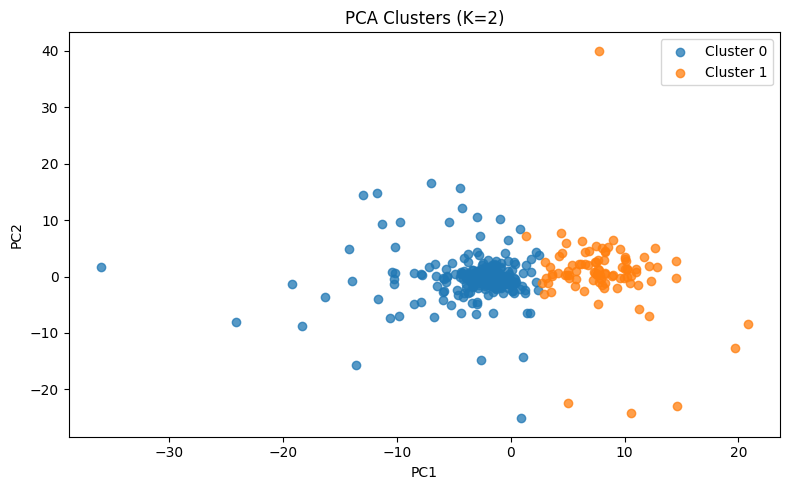

Variance shown: 44.94 %


In [ ]:
X_pca_2d = pca_shape.transform(X_shape_scaled)[:, :2]

plt.figure(figsize=(8, 5))
for cluster in sorted(np.unique(final_labels)):
    ids = final_labels == cluster
    plt.scatter(X_pca_2d[ids, 0], X_pca_2d[ids, 1], label=f"Cluster {cluster}", alpha=0.75)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Clusters (K=2)")
plt.legend()
plt.tight_layout()
plt.show()
print("Variance shown:", round(pca_shape.explained_variance_ratio_[:2].sum() * 100, 2), "%")

## Cluster Summary

The labels are arbitrary. The table below compares the groups using the original measurements.

In [ ]:
raw_stats = pd.DataFrame({
    "series_id": series_ids,
    "Cluster": final_labels,
    "mean": X.mean(axis=1).to_numpy(),
    "median": X.median(axis=1).to_numpy(),
    "std": X.std(axis=1).to_numpy(),
    "max": X.max(axis=1).to_numpy()
})
raw_stats["cv"] = raw_stats["std"] / raw_stats["mean"].replace(0, np.nan)
raw_stats["peak_to_average"] = raw_stats["max"] / raw_stats["mean"].replace(0, np.nan)

cluster_summary = raw_stats.groupby("Cluster").agg(
    Profiles=("series_id", "count"),
    Median_mean=("mean", "median"),
    Median_std=("std", "median"),
    Median_CV=("cv", "median"),
    Median_peak_to_average=("peak_to_average", "median")
)
display(cluster_summary.round(3))

,Profiles,Median_mean,Median_std,Median_CV,Median_peak_to_average
Cluster,,,,,
0,227,131134.077,16000.069,0.104,1.279
1,92,47710.125,7353.791,0.143,1.376


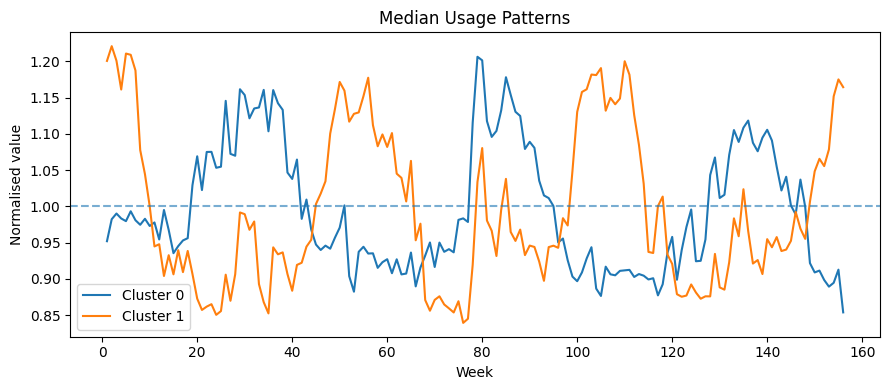

In [ ]:
shape_with_labels = X_shape.reset_index(drop=True).copy()
shape_with_labels["Cluster"] = final_labels
median_shape = shape_with_labels.groupby("Cluster")[week_columns].median()

plt.figure(figsize=(9, 4))
for cluster in median_shape.index:
    plt.plot(range(1, len(week_columns) + 1), median_shape.loc[cluster], label=f"Cluster {cluster}")
plt.axhline(1, linestyle="--", alpha=0.6)
plt.xlabel("Week")
plt.ylabel("Normalised value")
plt.title("Median Usage Patterns")
plt.legend()
plt.tight_layout()
plt.show()

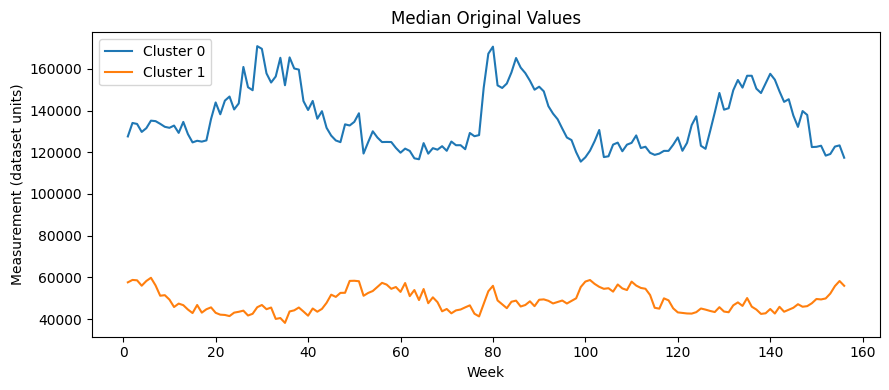

In [ ]:
X_with_labels = X.reset_index(drop=True).copy()
X_with_labels["Cluster"] = final_labels
median_raw = X_with_labels.groupby("Cluster")[week_columns].median()

plt.figure(figsize=(9, 4))
for cluster in median_raw.index:
    plt.plot(range(1, len(week_columns) + 1), median_raw.loc[cluster], label=f"Cluster {cluster}")
plt.xlabel("Week")
plt.ylabel("Measurement (dataset units)")
plt.title("Median Original Values")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

- 319 profiles were used after excluding T183 and T299 because of long zero blocks.
- Shape-based PCA retained 95.173% of variance with 25 components.
- K=2 gave a silhouette score of 0.3423, so separation is moderate rather than strong.
- Cluster 0 has higher typical measurement levels; Cluster 1 has greater relative variability.

The file does not establish why these patterns occur. The measurements are labelled in dataset units because the units of the weekly aggregation were not verified here.

## Source

Electricity weekly time series from the Monash Time Series Forecasting Repository, derived from the UCI ElectricityLoadDiagrams20112014 dataset.

- https://zenodo.org/records/3898436
- https://archive.ics.uci.edu/dataset/321/electricityloaddiagrams20112014
- https://github.com/laiguokun/multivariate-time-series-data